In [1]:
import os
import random
import numpy as np
import pandas as pd

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

In [2]:
file_paths = {
    "Loc1": "Location1.csv",
    "Loc2": "Location2.csv"
}

def dataset_ayarlama(file_paths):

    for loc_name, path in file_paths.items():
        df = pd.read_csv(path)
        
        # B) TARİH VE ZAMAN DÖNGÜSEL (CYCLIC) ÖZNİTELİKLERİ
        df['Time'] = pd.to_datetime(df['Time'])
        df['hour'] = df['Time'].dt.hour
        df['month'] = df['Time'].dt.month
        df['dayofweek'] = df['Time'].dt.dayofweek
        
        # Saatlik ve Aylık Sin/Cos Dönüşümleri (24 saat ve 12 ay döngüsü için)
        df['sin_hour'] = np.sin(2 * np.pi * df['hour'] / 24.0)
        df['cos_hour'] = np.cos(2 * np.pi * df['hour'] / 24.0)
        df['sin_month'] = np.sin(2 * np.pi * df['month'] / 12.0)
        df['cos_month'] = np.cos(2 * np.pi * df['month'] / 12.0)
        
        # C) RÜZGAR YÖNÜ DÖNGÜSEL (CYCLIC) DÖNÜŞÜMLERİ (1°-359° Çelişkisini Çözer)
        # Dereceler radyana çevrilip Sin ve Cosine bileşenleri alınır
        df['wind_dir_100m_sin'] = np.sin(np.radians(df['winddirection_100m']))
        df['wind_dir_100m_cos'] = np.cos(np.radians(df['winddirection_100m']))
        
        # 100 metre için rüzgar yönüyle yüksek korelasyona sahip olduğundan
        # ve rüzgar kayma katsayısının yeterli olmasından ötürü 10 metre için rüzgar yönü alınmayacak
        # df['wind_dir_10m_sin'] = np.sin(np.radians(df['winddirection_10m']))
        # df['wind_dir_10m_cos'] = np.cos(np.radians(df['winddirection_10m']))
        
        # D) METEOROLOJİK FİZİK TABANLI TÜREV ÖZNİTELİKLER
        # Epsilon (0.001) ile 0'a bölünme hataları önlenir
        eps = 0.001
        
        # 1. Rüzgar Kayma Katsayısı (Wind Shear Ratio)
        df['wind_shear_ratio'] = df['windspeed_100m'] / (df['windspeed_10m'] + eps)
        
        # 2. Türbülans ve Gust Oranı (Gust Ratio - 10m Gust'ın bağıl etkisi)
        df['gust_ratio'] = df['windgusts_10m'] / (df['windspeed_10m'] + eps)
        
        # 3. Çiğ Noktası Açığı (Sıcaklık ve Nem Doygunluk Farkı)
        df['temp_dew_spread'] = df['temperature_2m'] - df['dewpoint_2m']
        
        # E) ZAMAN SERİSİ GECİKME (LAG) ÖZNİTELİKLERİ
        df['windspeed_100m_lag1'] = df['windspeed_100m'].shift(1)
        df['Power_lag1'] = df['Power'].shift(1)

        # F) 1 SAATLİK GECİKME SUTÜNUNA BAĞLILIĞI KIRMAK İÇİN HAREKET YÖNÜ 
        df['Power_diff1'] = df['Power_lag1'] - df['Power'].shift(2)
        df['windspeed_100m_diff1'] = df['windspeed_100m_lag1'] - df['windspeed_100m'].shift(2)

        
        # F) GEREKSİZ / YÜKSEK KORELASYONLU HAM SÜTUNLARIN TEMİZLENMESİ (DROP)
        # - windspeed_10m: 100m ile +0.90 korelasyonlu, bilgisi wind_shear_ratio'ya aktarıldı
        # - dewpoint_2m: Sıcaklık ile yüksek korelasyonlu, bilgisi temp_dew_spread'e aktarıldı
        # - windgusts_10m: Mutlak değeri silindi, bilgisi gust_ratio'ya aktarıldı
        # - winddirection_10m / 100m: Derece hali silindi, Sin/Cos bileşenleri korundu
        # - Time, hour, month: Ham halleri çıkarıldı. Döngüsel halleri tutuldu
        # - Bağıl nem (relativehumidity_2m) ile Çiğ noktası açığı yüksek korelasyonlu (-0.98). relativehumidity_2m silindi
        drop_cols = [
            'Time', 'hour', 'month', 'dewpoint_2m', 'windspeed_10m', 
            'windgusts_10m', 'winddirection_10m', 'winddirection_100m', 'relativehumidity_2m'
        ]
        df = df.drop(columns=drop_cols, errors='ignore')
        
        # G) YENİ DOSYALARI KAYDETME ADIMI
        
        output_path = f"yeni_{os.path.basename(path)}"
        
        # index=False yaparak gereksiz indeks sütunu oluşmasını engelliyoruz
        df.to_csv(output_path, index=False)
        print(f"-> Başarıyla kaydedildi: {output_path}\n")

dataset_ayarlama(file_paths)

-> Başarıyla kaydedildi: yeni_Location1.csv

-> Başarıyla kaydedildi: yeni_Location2.csv



In [4]:
# Veri Setini Yükleme
df1 = pd.read_csv("yeni_Location1.csv")
df2 = pd.read_csv("yeni_Location2.csv")


# ZAMAN SERİSİ VERİ BÖLME FONKSİYONU
def split_time_series_data(df, target_col='Power', train_ratio=0.70, val_ratio=0.15):

    df.dropna(inplace=True)
    df.reset_index(drop=True, inplace=True)
    
    # Zaman serisi verisini kronolojik sırayı bozmadan Train, Validation ve Test olarak böler.
    n = len(df)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))
    
    # Özellikler (X) ve Hedef Değişken (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]
    
    # Bölme İşlemleri
    X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
    X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
    X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]
    
    return X_train, y_train, X_val, y_val, X_test, y_test

# SETLERİN OLUŞTURULMASI
# A) LOKASYON 1 VERİ SETİ BÖLME
df_loc1 = df1
X_tr_l1, y_tr_l1, X_val_l1, y_val_l1, X_te_l1, y_te_l1 = split_time_series_data(df_loc1)

# B) LOKASYON 2 VERİ SETİ BÖLME
df_loc2 = df2
X_tr_l2, y_tr_l2, X_val_l2, y_val_l2, X_te_l2, y_te_l2 = split_time_series_data(df_loc2)


# KONTROL VE BOYUT ÖZETİ
print(" ZAMANSAL VERİ BÖLME ÖZETİ ")

print("\n--- Lokasyon 1 Setleri ---")
print(f"Train: {X_tr_l1.shape[0]} satır | Val: {X_val_l1.shape[0]} satır | Test: {X_te_l1.shape[0]} satır")
print(f"Girdi Öznitelik Sayısı (Feature Count): {X_tr_l1.shape[1]}")

print("\n--- Lokasyon 2 Setleri ---")
print(f"Train: {X_tr_l2.shape[0]} satır | Val: {X_val_l2.shape[0]} satır | Test: {X_te_l2.shape[0]} satır")
print(f"Girdi Öznitelik Sayısı (Feature Count): {X_tr_l2.shape[1]}")

 ZAMANSAL VERİ BÖLME ÖZETİ 

--- Lokasyon 1 Setleri ---
Train: 30658 satır | Val: 6570 satır | Test: 6570 satır
Girdi Öznitelik Sayısı (Feature Count): 16

--- Lokasyon 2 Setleri ---
Train: 30658 satır | Val: 6570 satır | Test: 6570 satır
Girdi Öznitelik Sayısı (Feature Count): 16


In [6]:
X_tr_l1.head()

,temperature_2m,windspeed_100m,dayofweek,sin_hour,cos_hour,sin_month,cos_month,wind_dir_100m_sin,wind_dir_100m_cos,wind_shear_ratio,gust_ratio,temp_dew_spread,windspeed_100m_lag1,Power_lag1,Power_diff1,windspeed_100m_diff1
0,26.8,2.78,0,0.500000,8.660254e-01,0.5,0.866025,0.500000,-0.866025,2.136818,2.459646,2.3,3.99,0.1424,-0.0211,2.73
1,27.4,2.69,0,0.707107,7.071068e-01,0.5,0.866025,0.965926,-0.258819,2.067640,1.229823,3.1,2.78,0.1214,-0.0210,-1.21
2,27.3,4.43,0,0.866025,5.000000e-01,0.5,0.866025,0.994522,0.104528,1.792796,1.618778,3.2,2.69,0.1003,-0.0211,-0.09
3,27.6,5.59,0,0.965926,2.588190e-01,0.5,0.866025,0.984808,0.173648,2.046869,1.647748,2.4,4.43,0.0793,-0.0210,1.74
4,26.7,5.82,0,1.000000,6.123234e-17,0.5,0.866025,0.978148,0.207912,2.770109,2.237030,1.8,5.59,0.0778,-0.0015,1.16


In [7]:
df1.head()

,temperature_2m,windspeed_100m,Power,dayofweek,sin_hour,cos_hour,sin_month,cos_month,wind_dir_100m_sin,wind_dir_100m_cos,wind_shear_ratio,gust_ratio,temp_dew_spread,windspeed_100m_lag1,Power_lag1,Power_diff1,windspeed_100m_diff1
0,26.8,2.78,0.1214,0,0.500000,8.660254e-01,0.5,0.866025,0.500000,-0.866025,2.136818,2.459646,2.3,3.99,0.1424,-0.0211,2.73
1,27.4,2.69,0.1003,0,0.707107,7.071068e-01,0.5,0.866025,0.965926,-0.258819,2.067640,1.229823,3.1,2.78,0.1214,-0.0210,-1.21
2,27.3,4.43,0.0793,0,0.866025,5.000000e-01,0.5,0.866025,0.994522,0.104528,1.792796,1.618778,3.2,2.69,0.1003,-0.0211,-0.09
3,27.6,5.59,0.0778,0,0.965926,2.588190e-01,0.5,0.866025,0.984808,0.173648,2.046869,1.647748,2.4,4.43,0.0793,-0.0210,1.74
4,26.7,5.82,0.0959,0,1.000000,6.123234e-17,0.5,0.866025,0.978148,0.207912,2.770109,2.237030,1.8,5.59,0.0778,-0.0015,1.16


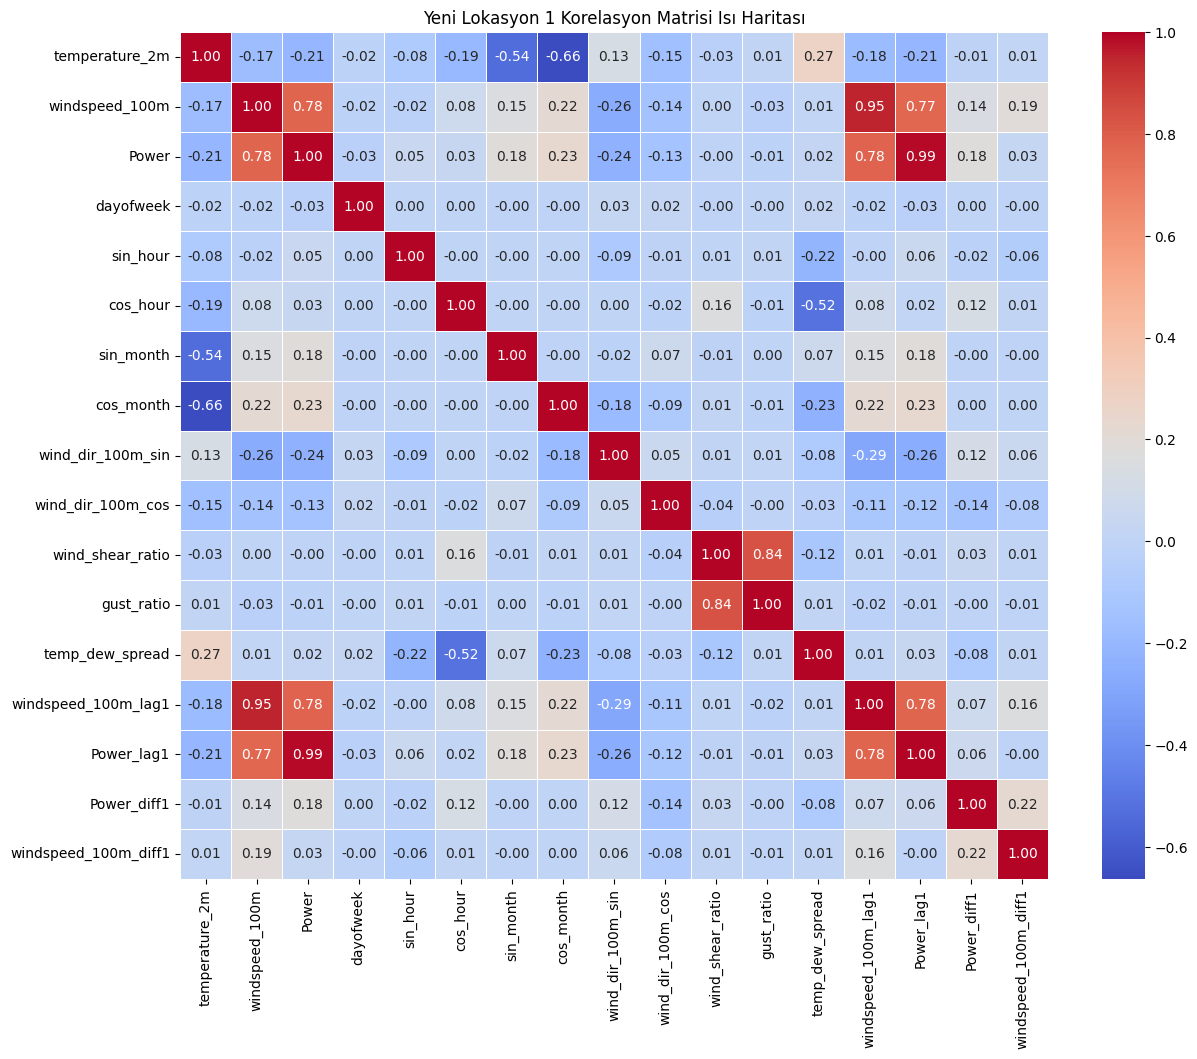

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Korelasyon matrisi
sayisal_df = df1.select_dtypes(include=['number'])
korelasyon_matrisi = sayisal_df.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(korelasyon_matrisi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Yeni Lokasyon 1 Korelasyon Matrisi Isı Haritası')
plt.savefig("yeni_lokasyon1_korelasyon_matrisi.png", dpi=300)
plt.show()

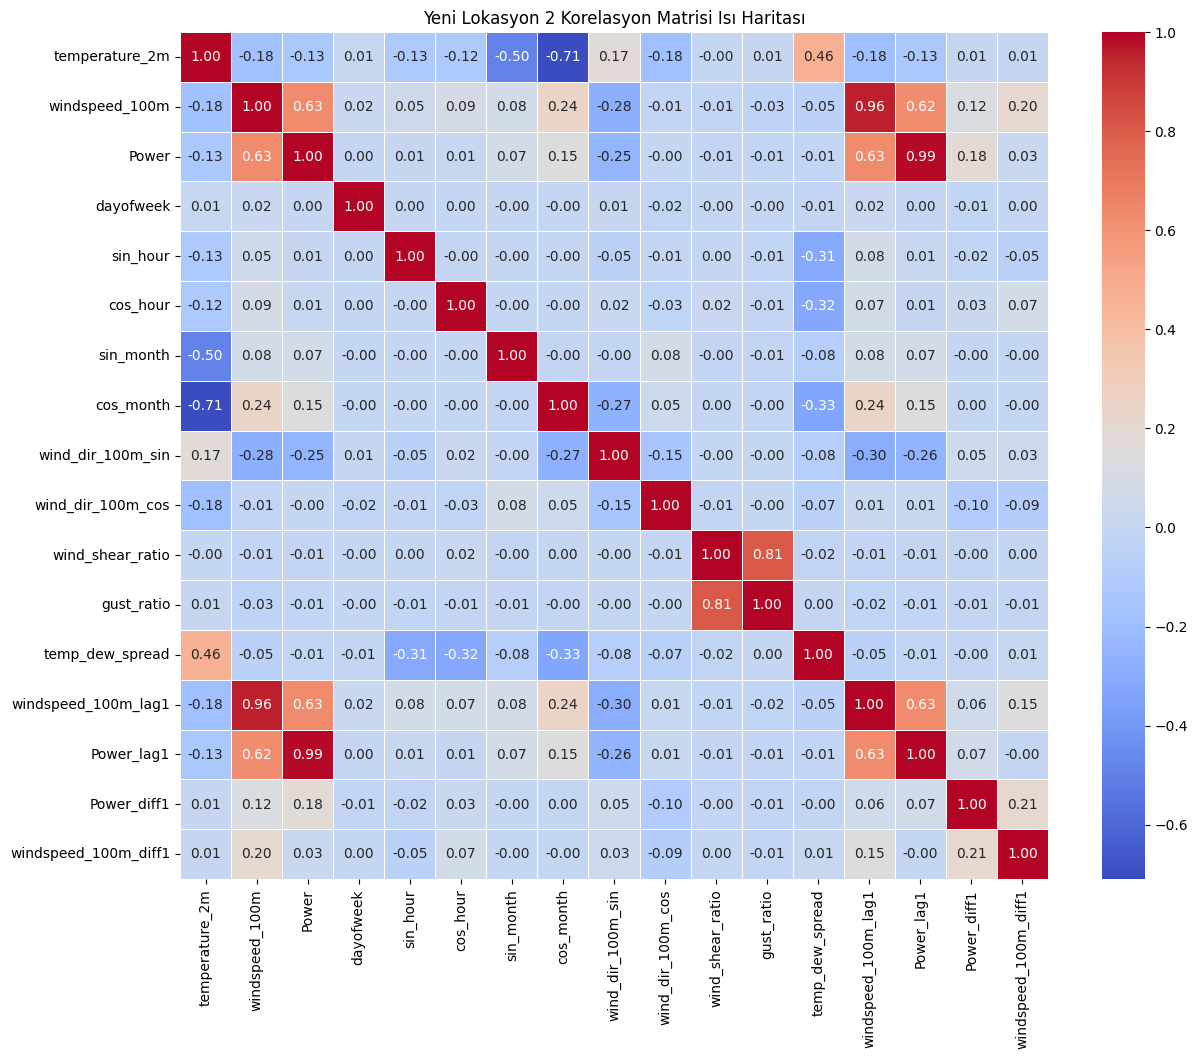

In [11]:
# Korelasyon matrisi
sayisal_df2 = df2.select_dtypes(include=['number'])
korelasyon_matrisi2 = sayisal_df2.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(korelasyon_matrisi2, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Yeni Lokasyon 2 Korelasyon Matrisi Isı Haritası')
plt.savefig("yeni_lokasyon2_korelasyon_matrisi.png", dpi=300)
plt.show()